# AI-Based Crop Disease Detection Using Deep Learning

**Framework:** TensorFlow / Keras  
**Model:** MobileNetV2 transfer learning  
**Dataset:** PlantVillage (38 image classes)  
**SDG alignment:** SDG 2 – Zero Hunger

## What this notebook does
1. Downloads and inspects the PlantVillage dataset.
2. Randomly separates examples into training, validation and test sets.
3. Resizes and preprocesses images for MobileNetV2.
4. Trains a TensorFlow image classifier.
5. Evaluates it using accuracy, precision, recall, F1-score and a confusion matrix.
6. Saves the model and class names, then launches an image-upload demo.

**Important:** Run every cell from top to bottom in a Google Colab GPU runtime. Do not report any accuracy number until the model has actually finished training and evaluation. This is an educational screening prototype, not a replacement for an agronomist's diagnosis.

## 0. Google Colab setup

1. Open **https://colab.research.google.com/**.
2. Choose **File → Upload notebook** and upload this `.ipynb` file.
3. Choose **Runtime → Change runtime type → T4 GPU** (or any available GPU). If no GPU is available, use CPU but expect training to take longer.
4. Run each cell using the play button on its left.

PlantVillage contains 54,303 images across 38 categories. The TFDS download is approximately 828 MiB, so use a stable internet connection and allow space/time for the download.

In [1]:
# Install TensorFlow Datasets. TensorFlow itself is normally preinstalled in Colab.
!pip -q install tensorflow-datasets scikit-learn matplotlib gradio

In [2]:
import os
import json
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5
AUTOTUNE = tf.data.AUTOTUNE

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("WARNING: No GPU detected. Training can be slow. Try Runtime > Change runtime type > GPU.")

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Download and inspect the dataset

We use the PlantVillage dataset through TensorFlow Datasets. Its published catalogue describes 54,303 images in 38 classes. We request the image bytes without decoding first so the dataset can be shuffled before it is split.

In [2]:
# Download/load PlantVillage. First run downloads about 828 MiB.
(raw_dataset, dataset_info) = tfds.load(
    "plant_village",
    split="train",
    as_supervised=False,
    with_info=True,
    decoders={"image": tfds.decode.SkipDecoding()},
)

CLASS_NAMES = dataset_info.features["label"].names
NUM_CLASSES = len(CLASS_NAMES)
TOTAL_IMAGES = dataset_info.splits["train"].num_examples

print("Total images:", TOTAL_IMAGES)
print("Number of classes:", NUM_CLASSES)
print("First 10 classes:", CLASS_NAMES[:10])
assert NUM_CLASSES == 38, "Unexpected dataset version/class count. Inspect CLASS_NAMES before continuing."

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.MCVZJT_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Total images: 54303
Number of classes: 38
First 10 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy']


In [4]:

!pip install -q importlib-resources etils[epath]

print("Missing dependencies installed successfully!")


Missing dependencies installed successfully!


In [4]:

!pip install -q --upgrade tensorflow-datasets tensorflow-metadata
print("Dataset dependencies installed!")


Dataset dependencies installed!


In [1]:

import importlib_resources
import tensorflow as tf
import tensorflow_datasets as tfds

print("Importlib Resources: SUCCESS")
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("ALL LIBRARIES LOADED SUCCESSFULLY!")


Importlib Resources: SUCCESS
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
ALL LIBRARIES LOADED SUCCESSFULLY!


## 2. Random train / validation / test split

The source dataset provides one training split, so this notebook shuffles the examples and creates our own 70% / 15% / 15% split. The test split is held back until final evaluation. A fixed seed makes the split reproducible.

In [4]:

# Set a fixed random seed for reproducibility
SEED = 42

print("Random seed initialized:", SEED)


Random seed initialized: 42


In [5]:
# Full-buffer shuffle gives a strong random permutation before creating splits.
# The examples are still encoded image bytes at this point to reduce shuffle memory use.
shuffled = raw_dataset.shuffle(
    buffer_size=TOTAL_IMAGES,
    seed=SEED,
    reshuffle_each_iteration=False,
)

train_count = int(TOTAL_IMAGES * 0.70)
val_count = int(TOTAL_IMAGES * 0.15)
test_count = TOTAL_IMAGES - train_count - val_count

train_raw = shuffled.take(train_count)
remaining = shuffled.skip(train_count)
val_raw = remaining.take(val_count)
test_raw = remaining.skip(val_count)

print(f"Train: {train_count:,} | Validation: {val_count:,} | Test: {test_count:,}")

Train: 38,012 | Validation: 8,145 | Test: 8,146


## 3. Preprocess images

Every image is decoded as RGB, resized to 224 × 224, and passed through MobileNetV2's required preprocessing function. That function scales pixels to the range expected by the pretrained MobileNetV2 network.

In [8]:

# Automatically optimize data loading performance
AUTOTUNE = tf.data.AUTOTUNE

print("AUTOTUNE initialized successfully!")


AUTOTUNE initialized successfully!


In [10]:

# PlantGuard - Image preprocessing configuration

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Preprocessing configuration ready!")


Image size: (224, 224)
Batch size: 32
Preprocessing configuration ready!


In [12]:

# Required libraries for image visualization
import numpy as np
import matplotlib.pyplot as plt

print("NumPy loaded successfully!")
print("Matplotlib loaded successfully!")


NumPy loaded successfully!
Matplotlib loaded successfully!


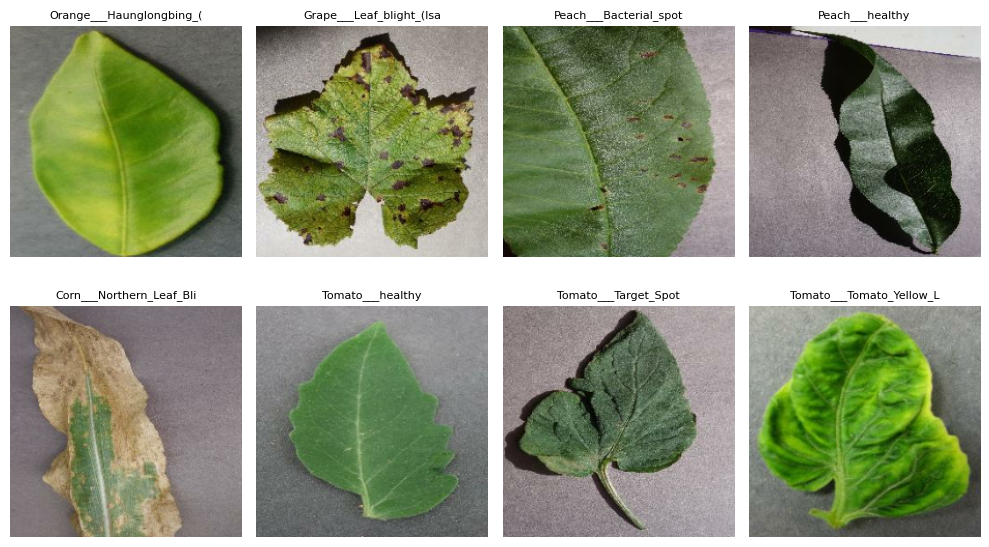

In [13]:
def preprocess_example(example):
    image = tf.io.decode_image(
        example["image"], channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    label = tf.cast(example["label"], tf.int32)
    return image, label

train_ds = (
    train_raw.map(preprocess_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
val_ds = (
    val_raw.map(preprocess_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
test_ds = (
    test_raw.map(preprocess_example, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Display a few preprocessed images (rescaled only for visualization).
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 6))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    display_img = (images[i].numpy() + 1.0) / 2.0
    plt.imshow(np.clip(display_img, 0, 1))
    plt.title(CLASS_NAMES[int(labels[i])][:24], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 4. Build the deep learning model

MobileNetV2 is a CNN pretrained on ImageNet. We remove its original 1,000-class output layer, freeze its feature-extraction layers, and attach a new classifier with 38 outputs for the PlantVillage classes. We train this new classification head on our dataset.

In [14]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.08),
    ],
    name="data_augmentation",
)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMAGE_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,), name="leaf_image")
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="disease_probabilities")(x)

model = tf.keras.Model(inputs, outputs, name="crop_disease_mobilenetv2")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "crop_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_probabilities (Dense)   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Train the model

An epoch is one pass through the training dataset. Validation data helps us monitor generalization during training; it is not used to update the model weights.

In [15]:

EPOCHS = 5

print("Training epochs:", EPOCHS)


Training epochs: 5


In [16]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_crop_disease_model.keras", monitor="val_loss", save_best_only=True
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

# Save final in-memory model too.
model.save("crop_disease_model.keras")

Epoch 1/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 106s 77ms/step - accuracy: 0.8510 - loss: 0.5379 - val_accuracy: 0.9346 - val_loss: 0.2217
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 136s 77ms/step - accuracy: 0.9269 - loss: 0.2388 - val_accuracy: 0.9454 - val_loss: 0.1811
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 96s 78ms/step - accuracy: 0.9369 - loss: 0.1982 - val_accuracy: 0.9497 - val_loss: 0.1581
Epoch 4/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 94s 77ms/step - accuracy: 0.9406 - loss: 0.1818 - val_accuracy: 0.9525 - val_loss: 0.1469
Epoch 5/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 93s 76ms/step - accuracy: 0.9448 - loss: 0.1710 - val_accuracy: 0.9497 - val_loss: 0.1563


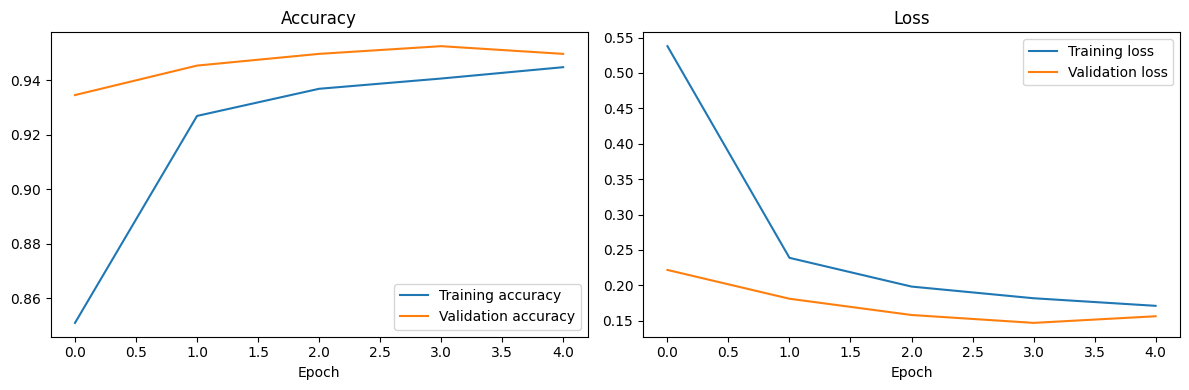

In [17]:
# Plot training and validation accuracy/loss.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=160)
plt.show()

## 6. Evaluate on the held-out test set

The test set is used only after training. Accuracy alone can hide class-wise weaknesses, so we also calculate precision, recall and F1-score for every class and plot a confusion matrix.

In [18]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

all_true = []
all_pred = []
for batch_images, batch_labels in test_ds:
    probabilities = model.predict(batch_images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    all_true.extend(batch_labels.numpy().tolist())
    all_pred.extend(predictions.tolist())

print("\nClassification report:")
report_text = classification_report(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0,
)
print(report_text)
with open("classification_report.txt", "w", encoding="utf-8") as f:
    f.write(report_text)

cm = confusion_matrix(all_true, all_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(18, 16))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
display.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
plt.title("PlantVillage Test-Set Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=180)
plt.show()

# Save the metric values for the report (actual measured values).
metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "num_classes": int(NUM_CLASSES),
    "dataset_total_images": int(TOTAL_IMAGES),
    "train_images": int(train_count),
    "validation_images": int(val_count),
    "test_images": int(test_count),
}
with open("evaluation_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)
print("Saved evaluation_metrics.json")

255/255 ━━━━━━━━━━━━━━━━━━━━ 19s 59ms/step - accuracy: 0.9511 - loss: 0.1463
Test loss: 0.1463
Test accuracy: 0.9511

Classification report:


NameError: name 'classification_report' is not defined

========== CLASSIFICATION REPORT ==========
                                               precision    recall  f1-score   support

                           Apple___Apple_scab       0.93      0.95      0.94        92
                            Apple___Black_rot       0.99      0.92      0.95        98
                     Apple___Cedar_apple_rust       0.90      1.00      0.95        46
                              Apple___healthy       0.97      0.99      0.98       244
                          Blueberry___healthy       1.00      0.99      0.99       215
                             Cherry___healthy       0.95      0.99      0.97       141
                      Cherry___Powdery_mildew       1.00      0.98      0.99       172
   Corn___Cercospora_leaf_spot Gray_leaf_spot       0.91      0.67      0.77        75
                           Corn___Common_rust       0.99      0.99      0.99       173
                               Corn___healthy       0.99      0.99      0.99       16

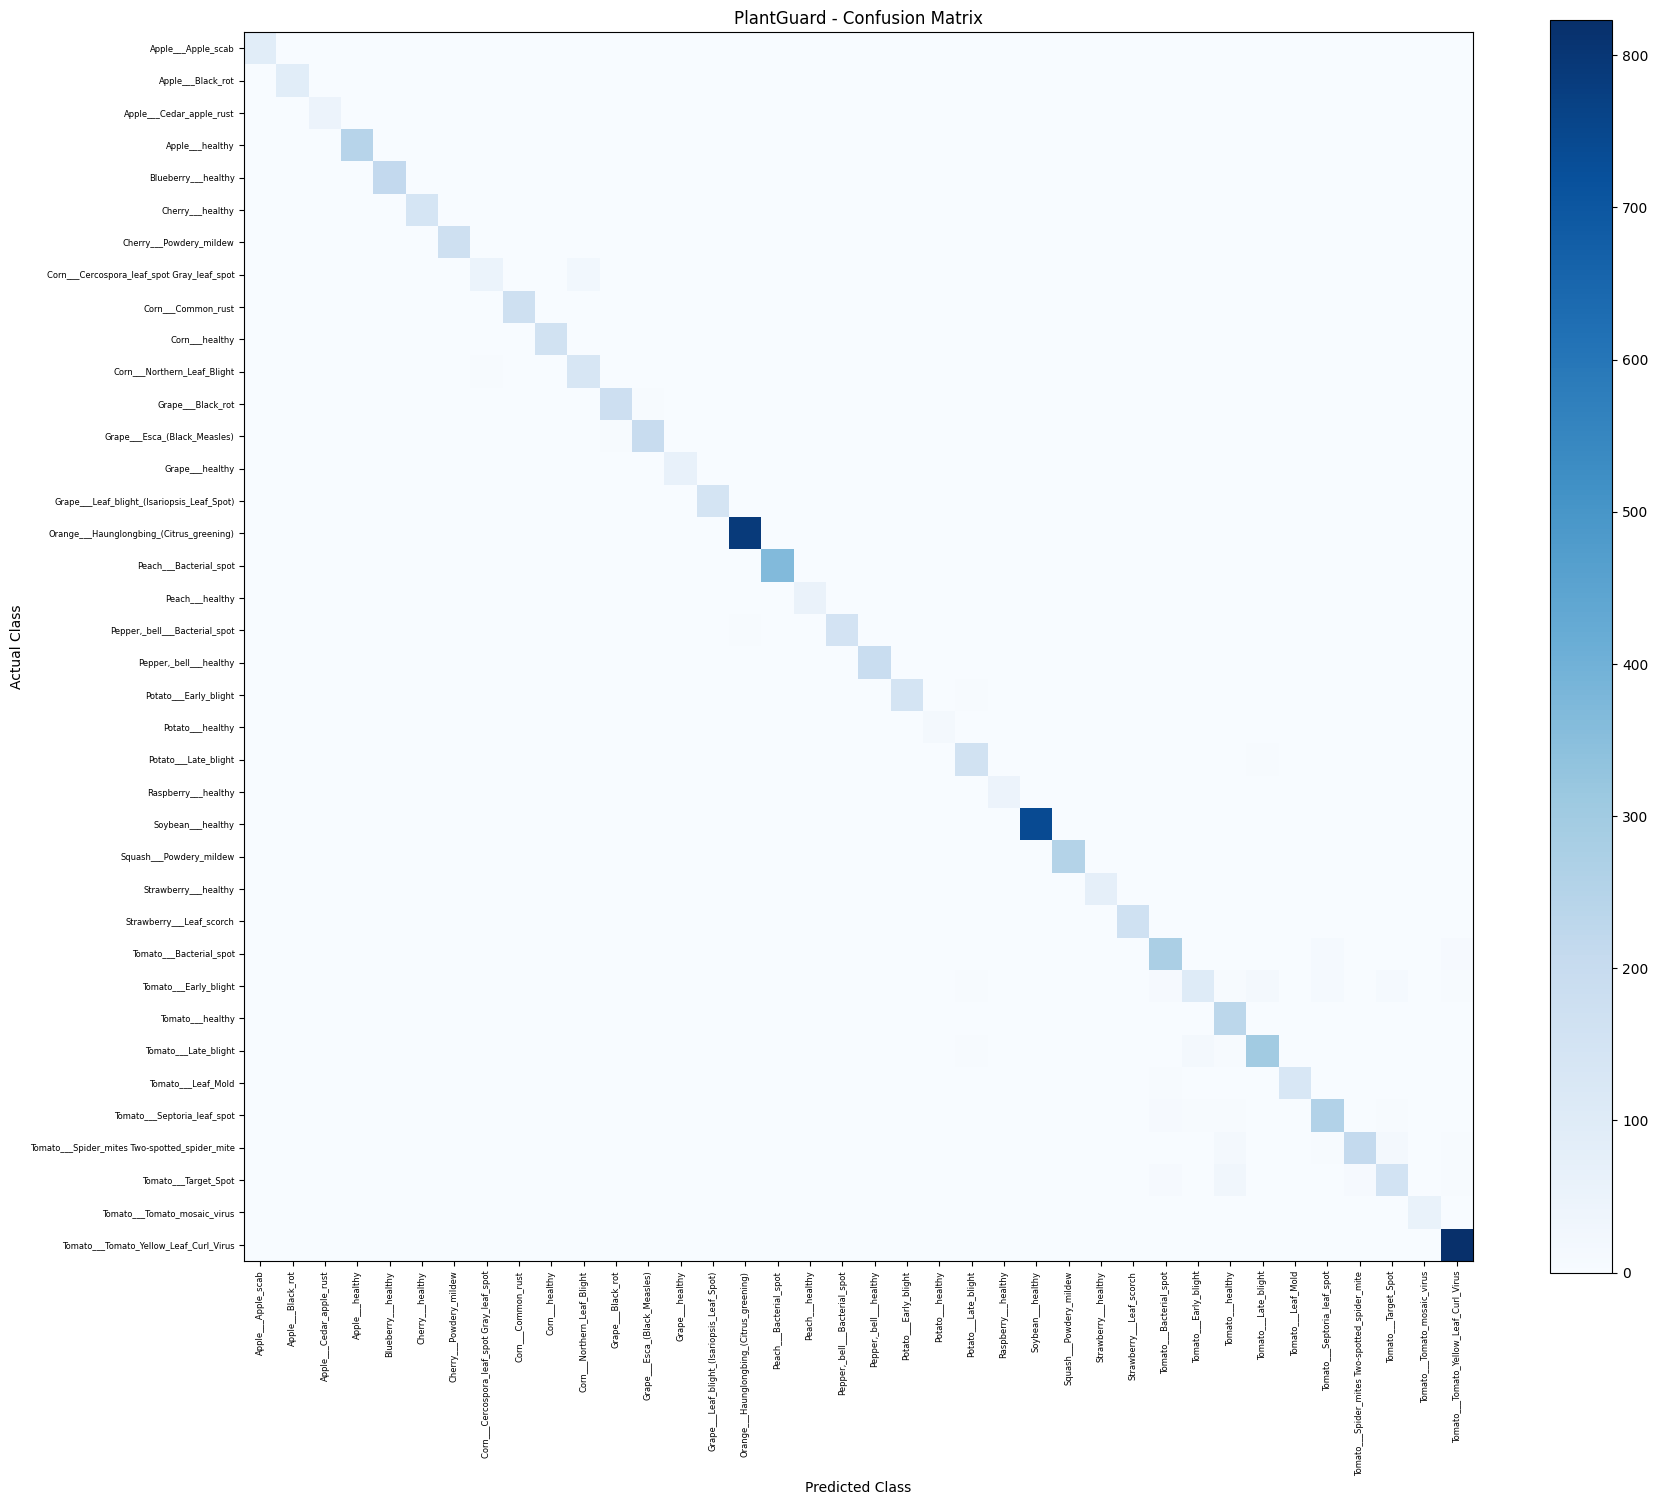

In [19]:

# Fix missing evaluation imports
from sklearn.metrics import classification_report, confusion_matrix

# Generate classification report
report_text = classification_report(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
)

print("========== CLASSIFICATION REPORT ==========")
print(report_text)

# Generate confusion matrix
cm = confusion_matrix(
    all_true,
    all_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(18, 15))
plt.imshow(cm, cmap="Blues")
plt.title("PlantGuard - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.colorbar()

plt.xticks(range(NUM_CLASSES), CLASS_NAMES,
           rotation=90, fontsize=6)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES,
           fontsize=6)

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()


## 7. Save class labels and create a prediction function

The saved class-name file is needed because the model outputs numeric class IDs. The helper below applies the exact same image size and MobileNetV2 preprocessing used during training.

In [21]:

# Fix missing imports for prediction
import json
import numpy as np
import tensorflow as tf
from PIL import Image

print("All prediction imports loaded successfully!")


All prediction imports loaded successfully!


In [22]:
with open("class_names.json", "w", encoding="utf-8") as f:
    json.dump(CLASS_NAMES, f, indent=2)

def predict_image_pil(pil_image):
    """Return top-5 class probabilities for a PIL image."""
    from PIL import Image
    if pil_image is None:
        raise ValueError("Please upload a leaf image.")
    image = pil_image.convert("RGB").resize(IMAGE_SIZE)
    array = np.asarray(image, dtype=np.float32)
    array = tf.keras.applications.mobilenet_v2.preprocess_input(array)
    batch = np.expand_dims(array, axis=0)
    probabilities = model.predict(batch, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:5]
    return {CLASS_NAMES[int(i)]: float(probabilities[i]) for i in top_indices}

print("Prediction helper is ready.")

Prediction helper is ready.


## 8. Launch the practical demonstration interface

Upload a leaf photograph to display the model's top predicted classes and confidence scores. The output is a model prediction, not a guaranteed agricultural diagnosis.

In [23]:
import gradio as gr


def classify_leaf(image):
    return predict_image_pil(image)

with gr.Blocks() as demo:
    gr.Markdown("# AI-Based Crop Disease Detection")
    gr.Markdown("Upload a crop-leaf image. This educational prototype predicts one of the PlantVillage classes.")
    image_input = gr.Image(type="pil", label="Upload leaf image")
    prediction_output = gr.Label(num_top_classes=5, label="Top predictions")
    predict_button = gr.Button("Predict disease")
    predict_button.click(classify_leaf, inputs=image_input, outputs=prediction_output)
    gr.Markdown("**Disclaimer:** Use this as a screening aid only. Confirm suspected disease with an agricultural expert.")

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1c1edb7aa4e2503ee7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [24]:

from google.colab import drive
drive.mount('/content/drive')


MessageError: Error: credential propagation was unsuccessful

## 9. Download your project results

After all cells finish, download these files from the Colab Files panel (folder icon on the left):
- `crop_disease_model.keras`
- `class_names.json`
- `evaluation_metrics.json`
- `classification_report.txt`
- `training_curves.png`
- `confusion_matrix.png`

Keep the notebook with its outputs as evidence of the actual implementation and evaluation.

## Dataset and model references

1. Hughes, D. P., & Salathé, M. (2015). *An open access repository of images on plant health to enable the development of mobile disease diagnostics through machine learning and crowdsourcing.* arXiv:1511.08060. https://arxiv.org/abs/1511.08060
2. TensorFlow Datasets, *PlantVillage dataset catalogue*. https://www.tensorflow.org/datasets/catalog/plant_village
3. TensorFlow / Keras, *MobileNetV2 API documentation*. https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2
4. Sandler, M. et al. (2018). *MobileNetV2: Inverted Residuals and Linear Bottlenecks.* CVPR. https://arxiv.org/abs/1801.04381

**Dataset note:** The TFDS catalogue states that it republishes an unaugmented version of PlantVillage sourced via a paper dataset, and excludes the `Background_without_leaves` label. Acknowledge the dataset and this source in the final report.